# 3D Jerk-Controlled Lattice Planning in JAX — Part 2: LQMT Heuristics & Pure-JAX Wavefront Search

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arunkumar-singh/drone_course_repo/blob/main/tutorials/quadrotor_lattice_search_3d_jerk_jax_colab.ipynb)

This second companion notebook implements **Sections III-C and III-D (Proposition 3 & Fig. 5)** of Liu et al. (2017), *Search-based Motion Planning for Quadrotors using Linear Quadratic Minimum Time Control* (`lattice_quad.pdf`), for the **3D jerk-controlled system ($n = 3$, $M = 27$ primitives)** in pure JAX:

1. **Problem 2 — Discrete Graph Search on the 3D Jerk Lattice (Sec. III-C)**: Starting from a moving state $\mathbf{s}_0 = [\mathbf{p}_0, \mathbf{v}_0, \mathbf{a}_0]^\top \in \mathbb{R}^{3 \times 3}$, we search over sequences of constant-jerk primitives $\mathbf{u}_k \in \mathcal{U}_{27} = \{-j_{\max}, 0, +j_{\max}\}^3$ of duration $\tau$ to reach $\mathbf{s}_g$ while minimizing cumulative effort plus time:
   $$\min_{\{\mathbf{u}_k\}_{k=0}^{N-1}} \sum_{k=0}^{N-1} \left(\|\mathbf{u}_k\|_2^2 + \rho\right)\tau.$$
2. **Block 1 — Admissible Heuristics $h_1$ (Min-Time) vs. $h_2$ (LQMT, Sec. III-D & Proposition 3)**: Compares the kinematic lower bound $h_1(\mathbf{s}) = \rho \bar{T}_v$ against the explicit Linear Quadratic Minimum-Time (LQMT) cost-to-go $h_2(\mathbf{s})$ computed via the $3 \times 3$ controllability Gramian $W_T$.
3. **Block 2 — Fully Tensorized Pure-JAX Wavefront Search (`jax.lax.while_loop`, Fig. 5)**: Executes Dijkstra ($h = 0$), $A^*$ with $h_1$, and $A^*$ with $h_2$ entirely inside XLA over fixed-capacity arrays (zero Python `heapq`), reproducing the dramatic node-expansion reduction of Fig. 5 in 9D state space.


In [1]:
import importlib.util
import subprocess
import sys
import time

_missing = []
try:
    import jax
    import jax.numpy as jnp
except ImportError:
    _missing.append("jax")

if importlib.util.find_spec("matplotlib") is None:
    _missing.append("matplotlib")

if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

# Preserve full float32 precision on CUDA GPUs (disable TF32 matmul rounding)
jax.config.update("jax_default_matmul_precision", "highest")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "legend.fontsize": 8.5,
})

# Compact Part-1 3D Jerk Lattice Kernel (n = 3, M = 27 primitives)
tau = 0.5
j_max = 2.0
v_max = 0.75
a_max = 1.0
rho = 20.0

u_1d = jnp.array([-j_max, 0.0, j_max])
ugx, ugy, ugz = jnp.meshgrid(u_1d, u_1d, u_1d, indexing="ij")
U_M = jnp.stack([ugx.reshape(-1), ugy.reshape(-1), ugz.reshape(-1)], axis=-1)  # (27, 3)
EDGE_COSTS = (jnp.sum(U_M**2, axis=-1) + rho) * tau                           # (27,)


def F_mat(t):
    return jnp.array([
        [1.0, t, 0.5 * t**2],
        [0.0, 1.0, t],
        [0.0, 0.0, 1.0],
    ])


def G_vec(t):
    return jnp.array([t**3 / 6.0, 0.5 * t**2, t])


obs_centers = jnp.array([[0.50, 0.0, 0.0]])
obs_radii = jnp.array([0.22])
t_check = jnp.linspace(0.0, tau, 9)


def eval_primitive(s, u):
    return jax.vmap(lambda t: F_mat(t) @ s + jnp.outer(G_vec(t), u))(t_check)


def get_successors(s):
    trajs = jax.vmap(eval_primitive, in_axes=(None, 0))(s, U_M)  # (27, 9, 3, 3)
    p_tr, v_tr, a_tr = trajs[:, :, 0, :], trajs[:, :, 1, :], trajs[:, :, 2, :]

    vel_ok = jnp.all(jnp.abs(v_tr) <= v_max + 1e-5, axis=(1, 2))
    acc_ok = jnp.all(jnp.abs(a_tr) <= a_max + 1e-5, axis=(1, 2))
    bounds_ok = (
        jnp.all((p_tr[:, :, 0] >= -0.05) & (p_tr[:, :, 0] <= 1.15), axis=1)
        & jnp.all((p_tr[:, :, 1] >= -0.05) & (p_tr[:, :, 1] <= 0.65), axis=1)
        & jnp.all((p_tr[:, :, 2] >= -0.05) & (p_tr[:, :, 2] <= 0.85), axis=1)
    )
    dists = jnp.linalg.norm(p_tr[:, :, None, :] - obs_centers[None, None, :, :], axis=-1)
    obs_ok = jnp.all(dists > obs_radii[None, None, :], axis=(1, 2))

    valid = vel_ok & acc_ok & bounds_ok & obs_ok
    return trajs[:, -1, :, :], valid, EDGE_COSTS


# Moving initial state s0 and reachable 3D goal lattice state s_goal (4-step detour around obstacle)
s0 = jnp.array([
    [0.0, 0.0, 0.0],   # p0 [m]
    [0.5, 0.0, 0.0],   # v0 [m/s]
    [0.0, 0.0, 0.0],   # a0 [m/s^2]
])
u_seq_demo = jnp.array([
    [0.0,  2.0,  2.0],
    [0.0, -2.0, -2.0],
    [0.0, -2.0,  0.0],
    [0.0,  2.0,  0.0],
])
s_goal = s0
for k in range(4):
    s_goal = F_mat(tau) @ s_goal + jnp.outer(G_vec(tau), u_seq_demo[k])


def is_goal(s):
    return jnp.max(jnp.abs(s - s_goal)) < 1e-4


print(f"JAX version: {jax.__version__} | Backend: {jax.default_backend()} | Devices: {jax.devices()}")
print(f"Control lattice U_M: {U_M.shape}, Edge costs range: [{float(EDGE_COSTS.min()):.1f}, {float(EDGE_COSTS.max()):.1f}]")
print(f"Start state s0   -> pos={s0[0].tolist()}, vel={s0[1].tolist()}, acc={s0[2].tolist()}")
print(f"Goal state s_goal -> pos={s_goal[0].tolist()}, vel={s_goal[1].tolist()}, acc={s_goal[2].tolist()}")


JAX version: 0.6.2 | Backend: gpu | Devices: [CudaDevice(id=0)]
Control lattice U_M: (27, 3), Edge costs range: [10.0, 16.0]


Start state s0   -> pos=[0.0, 0.0, 0.0], vel=[0.5, 0.0, 0.0], acc=[0.0, 0.0, 0.0]
Goal state s_goal -> pos=[1.0, 0.5000000596046448, 0.75], vel=[0.5, 0.0, 0.5], acc=[0.0, 0.0, 0.0]


---
## Block 1: Admissible Heuristics $h_1$ (Min-Time) vs. $h_2$ (LQMT, Proposition 3)

To guide $A^*$ search without sacrificing optimality, Section III-D constructs lower bounds on the true cost-to-go $C^*(\mathbf{s}, \mathbf{s}_g)$ by relaxing obstacle and input-discretization constraints:

1. **Minimum-Time Heuristic $h_1$ (Eq. 7)**: Drops control effort ($\|\mathbf{u}\|_2^2 \ge 0$) and bounds the remaining flight time via the per-axis speed limit $v_{\max}$:
   $$h_1(\mathbf{s}) = \rho \bar{T}_v, \qquad \bar{T}_v = \frac{\|\mathbf{p}_g - \mathbf{p}\|_\infty}{v_{\max}}.$$
   Because $h_1$ depends only on position $\mathbf{p}$, it ignores whether the current velocity $\mathbf{v}$ and acceleration $\mathbf{a}$ are pointed toward or away from $\mathbf{s}_g$.

2. **Linear Quadratic Minimum-Time (LQMT) Heuristic $h_2$ (Proposition 3, Eq. 8–10)**: Solves the continuous-time unconstrained optimal control problem from $\mathbf{s}$ to $\mathbf{s}_g$ over horizon $T \ge \bar{T}_v$. For $n = 3$ jerk control, the per-axis controllability Gramian $W_T = \int_0^T G(s)G(s)^\top ds$ and terminal state residual $\delta_T \in \mathbb{R}^{3 \times 3}$ are:
   $$W_T = \begin{bmatrix} \frac{T^5}{20} & \frac{T^4}{8} & \frac{T^3}{6} \\ \frac{T^4}{8} & \frac{T^3}{3} & \frac{T^2}{2} \\ \frac{T^3}{6} & \frac{T^2}{2} & T \end{bmatrix}, \qquad \delta_T = \mathbf{s}_g - F(T)\mathbf{s}, \qquad h_2(\mathbf{s}) = \min_{T \ge \bar{T}_v} \left(\operatorname{tr}\!\left(\delta_T^\top W_T^{-1} \delta_T\right) + \rho T\right).$$
   We evaluate `jnp.linalg.inv(W_mat(T))` across a candidate grid of durations $T \ge \bar{T}_v$ in parallel via `jax.vmap`. By construction, $0 \le h_1(\mathbf{s}) \le h_2(\mathbf{s}) \le C^*(\mathbf{s}, \mathbf{s}_g)$.


--- Admissibility & Tightness Check at Start State s0 ---
h0(s0) [Dijkstra] :   0.00
h1(s0) [Min-Time] :  26.67  (T_bar_v = 1.333 s)
h2(s0) [LQMT]     :  47.67
True Optimal Cost :  80.00  (0.00 <= 26.67 <= 47.67 <= 80.00)


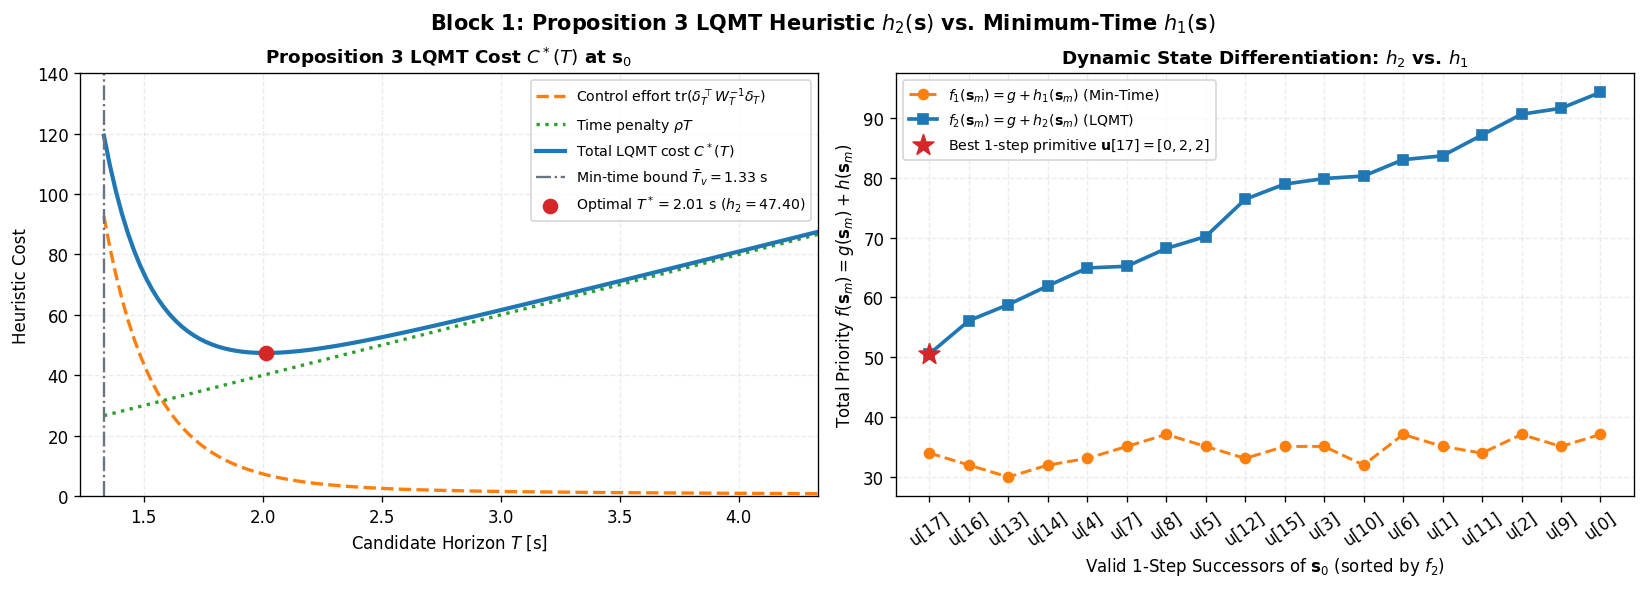

In [2]:
def W_mat(T):
    return jnp.array([
        [T**5 / 20.0, T**4 / 8.0, T**3 / 6.0],
        [T**4 / 8.0,  T**3 / 3.0, T**2 / 2.0],
        [T**3 / 6.0,  T**2 / 2.0, T],
    ])


def h_zero(s):
    return 0.0


def h_min_time(s):
    T_bar = jnp.max(jnp.abs(s_goal[0] - s[0])) / v_max
    return rho * T_bar


def lqmt_cost_T(s, T):
    delta = s_goal - F_mat(T) @ s
    W_inv = jnp.linalg.inv(W_mat(T))
    effort = jnp.sum(delta * (W_inv @ delta))
    return effort + rho * T


def h_lqmt(s):
    T_bar = jnp.maximum(jnp.max(jnp.abs(s_goal[0] - s[0])) / v_max, tau)
    T_grid = jnp.linspace(T_bar, T_bar + 3.0, 16)
    costs = jax.vmap(lqmt_cost_T, in_axes=(None, 0))(s, T_grid)
    return jnp.where(is_goal(s), 0.0, jnp.min(costs))


h0_val = float(h_zero(s0))
h1_val = float(h_min_time(s0))
h2_val = float(h_lqmt(s0))
J_star_true = 80.00

print("--- Admissibility & Tightness Check at Start State s0 ---")
print(f"h0(s0) [Dijkstra] : {h0_val:6.2f}")
print(f"h1(s0) [Min-Time] : {h1_val:6.2f}  (T_bar_v = {h1_val / rho:.3f} s)")
print(f"h2(s0) [LQMT]     : {h2_val:6.2f}")
print(f"True Optimal Cost : {J_star_true:6.2f}  (0.00 <= {h1_val:.2f} <= {h2_val:.2f} <= {J_star_true:.2f})")

# Evaluate C*(T) breakdown at s0 and 1-step successor f-values
T_bar_0 = float(jnp.max(jnp.abs(s_goal[0] - s0[0])) / v_max)
T_sweep = jnp.linspace(T_bar_0, T_bar_0 + 3.0, 120)
total_T = jax.vmap(lqmt_cost_T, in_axes=(None, 0))(s0, T_sweep)
time_T = rho * T_sweep
effort_T = total_T - time_T
best_T_idx = int(jnp.argmin(total_T))
T_star_0 = float(T_sweep[best_T_idx])
C_star_0 = float(total_T[best_T_idx])

s_next_0, valid_0, edge_0 = get_successors(s0)
valid_idx = jnp.where(valid_0)[0]
f_h1_valid = edge_0[valid_idx] + jax.vmap(h_min_time)(s_next_0[valid_idx])
f_h2_valid = edge_0[valid_idx] + jax.vmap(h_lqmt)(s_next_0[valid_idx])
order = jnp.argsort(f_h2_valid)
sorted_prim_ids = valid_idx[order]
f_h1_sorted = f_h1_valid[order]
f_h2_sorted = f_h2_valid[order]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13.6, 4.8), constrained_layout=True)

# Left: LQMT Cost Breakdown vs Horizon T
ax0.plot(T_sweep, effort_T, color="#ff7f0e", ls="--", lw=2.0, label=r"Control effort $\mathrm{tr}(\delta_T^\top W_T^{-1}\delta_T)$")
ax0.plot(T_sweep, time_T, color="#2ca02c", ls=":", lw=2.0, label=r"Time penalty $\rho T$")
ax0.plot(T_sweep, total_T, color="#1f77b4", lw=2.5, label=r"Total LQMT cost $C^*(T)$")
ax0.axvline(T_bar_0, color="#6b7280", ls="-.", lw=1.4, label=rf"Min-time bound $\bar{{T}}_v = {T_bar_0:.2f}$ s")
ax0.scatter([T_star_0], [C_star_0], color="#d62728", zorder=6, s=70, label=rf"Optimal $T^* = {T_star_0:.2f}$ s ($h_2 = {C_star_0:.2f}$)")
ax0.set_xlim(T_bar_0 - 0.1, float(T_sweep[-1]))
ax0.set_ylim(0.0, 140.0)
ax0.set_xlabel(r"Candidate Horizon $T$ [s]")
ax0.set_ylabel(r"Heuristic Cost")
ax0.set_title(r"Proposition 3 LQMT Cost $C^*(T)$ at $\mathbf{s}_0$")
ax0.legend(loc="upper right", frameon=True)

# Right: 1-Step Successor Priority f(s_m) = g(s_m) + h(s_m)
x_pos = jnp.arange(len(sorted_prim_ids))
labels = [f"u[{int(i)}]" for i in sorted_prim_ids]
ax1.plot(x_pos, f_h1_sorted, "o--", color="#ff7f0e", lw=1.8, ms=6, label=r"$f_1(\mathbf{s}_m) = g + h_1(\mathbf{s}_m)$ (Min-Time)")
ax1.plot(x_pos, f_h2_sorted, "s-", color="#1f77b4", lw=2.2, ms=6.5, label=r"$f_2(\mathbf{s}_m) = g + h_2(\mathbf{s}_m)$ (LQMT)")
ax1.scatter([0], [float(f_h2_sorted[0])], color="#d62728", marker="*", s=170, zorder=6, label=r"Best 1-step primitive $\mathbf{u}[17]=[0, 2, 2]$")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(labels, rotation=35)
ax1.set_xlabel(r"Valid 1-Step Successors of $\mathbf{s}_0$ (sorted by $f_2$)")
ax1.set_ylabel(r"Total Priority $f(\mathbf{s}_m) = g(\mathbf{s}_m) + h(\mathbf{s}_m)$")
ax1.set_title(r"Dynamic State Differentiation: $h_2$ vs. $h_1$")
ax1.legend(loc="upper left", frameon=True)

fig.suptitle(r"Block 1: Proposition 3 LQMT Heuristic $h_2(\mathbf{s})$ vs. Minimum-Time $h_1(\mathbf{s})$", fontsize=12.5, fontweight="bold")
plt.show()


---
## Block 2: Fully Tensorized Pure-JAX Wavefront Search (Sec. III-C & Fig. 5)

Instead of maintaining a Python `heapq` priority queue, we run the entire best-first graph search inside XLA via `jax.lax.while_loop` over fixed-capacity arrays (`MAX_NODES = 6500`):

- **State & Priority Tables**: `states` `(MAX_NODES, 3, 3)`, `g_cost` `(MAX_NODES,)`, `f_cost` `(MAX_NODES,)`, `closed` `(MAX_NODES,)`, `parent` `(MAX_NODES,)`, and `parent_u` `(MAX_NODES,)`.
- **Wavefront Selection**: Each iteration selects the open lattice node with minimum total priority via `curr_idx = jnp.argmin(f_cost)`, checks `is_goal(states[curr_idx])`, and marks `curr_idx` closed by setting `f_cost[curr_idx] = jnp.inf`.
- **Parallel Expansion**: `get_successors(s_curr)` and `jax.vmap(heuristic_fn)(s_next_all)` evaluate all $M = 27$ cubic 3D trajectories and their heuristic costs simultaneously on the GPU, then update matching or newly allocated lattice slots via `jax.lax.fori_loop`.


In [3]:
MAX_NODES = 6500


def run_jax_search(heuristic_fn):
    states = jnp.full((MAX_NODES, 3, 3), jnp.inf).at[0].set(s0)
    g_cost = jnp.full((MAX_NODES,), jnp.inf).at[0].set(0.0)
    f_cost = jnp.full((MAX_NODES,), jnp.inf).at[0].set(heuristic_fn(s0))
    closed = jnp.zeros((MAX_NODES,), dtype=bool)
    parent = jnp.full((MAX_NODES,), -1, dtype=jnp.int32)
    parent_u = jnp.full((MAX_NODES,), -1, dtype=jnp.int32)

    def cond_fn(carry):
        states, g_cost, f_cost, closed, parent, parent_u, n_alloc, n_exp, goal_idx = carry
        return (goal_idx < 0) & (jnp.min(f_cost) < jnp.inf) & (n_alloc < MAX_NODES - 27)

    def body_fn(carry):
        states, g_cost, f_cost, closed, parent, parent_u, n_alloc, n_exp, goal_idx = carry
        curr_idx = jnp.argmin(f_cost).astype(jnp.int32)
        s_curr = states[curr_idx]
        g_curr = g_cost[curr_idx]

        reached = is_goal(s_curr)
        goal_idx = jnp.where(reached, curr_idx, goal_idx)
        f_cost = f_cost.at[curr_idx].set(jnp.inf)
        closed = closed.at[curr_idx].set(True)
        n_exp = n_exp + jnp.where(reached, 0, 1)

        s_next_all, valid_all, edge_costs = get_successors(s_curr)
        h_all = jax.vmap(heuristic_fn)(s_next_all)

        def insert_one(m, inner_carry):
            states, g_cost, f_cost, closed, parent, parent_u, n_alloc = inner_carry
            valid = valid_all[m] & (~reached)
            s_m = s_next_all[m]
            new_g = g_curr + edge_costs[m]
            new_f = new_g + h_all[m]

            matches = jnp.max(jnp.abs(states - s_m), axis=(1, 2)) < 1e-4
            exists = jnp.any(matches)
            target_idx = jnp.where(exists, jnp.argmax(matches).astype(jnp.int32), n_alloc)
            improve = valid & ((~exists) | ((new_g < g_cost[target_idx]) & (~closed[target_idx])))

            states = jnp.where(improve & (~exists), states.at[target_idx].set(s_m), states)
            g_cost = jnp.where(improve, g_cost.at[target_idx].set(new_g), g_cost)
            f_cost = jnp.where(improve, f_cost.at[target_idx].set(new_f), f_cost)
            parent = jnp.where(improve, parent.at[target_idx].set(curr_idx), parent)
            parent_u = jnp.where(improve, parent_u.at[target_idx].set(m), parent_u)
            n_alloc = n_alloc + jnp.where(improve & (~exists), 1, 0)
            return (states, g_cost, f_cost, closed, parent, parent_u, n_alloc)

        states, g_cost, f_cost, closed, parent, parent_u, n_alloc = jax.lax.fori_loop(
            0, 27, insert_one, (states, g_cost, f_cost, closed, parent, parent_u, n_alloc)
        )
        return (states, g_cost, f_cost, closed, parent, parent_u, n_alloc, n_exp, goal_idx)

    init_carry = (states, g_cost, f_cost, closed, parent, parent_u, jnp.int32(1), jnp.int32(0), jnp.int32(-1))
    return jax.lax.while_loop(cond_fn, body_fn, init_carry)


def extract_optimal_trajectory(states, parent, parent_u, goal_idx):
    node_chain, u_indices = [int(goal_idx)], []
    curr = int(goal_idx)
    while int(parent[curr]) >= 0:
        u_indices.append(int(parent_u[curr]))
        curr = int(parent[curr])
        node_chain.append(curr)
    node_chain.reverse()
    u_indices.reverse()
    return states[jnp.array(node_chain)], U_M[jnp.array(u_indices)]


search_results = {}
print("--- Pure-JAX 3D Jerk Lattice Search Benchmark (n=3, M=27) ---")
for label, h_fn in [
    ("Dijkstra (h=0)", h_zero),
    ("A* with h1 (Min-Time)", h_min_time),
    ("A* with h2 (LQMT)", h_lqmt),
]:
    jit_search = jax.jit(lambda h=h_fn: run_jax_search(h))
    out = jit_search()
    jax.block_until_ready(out[-1])

    t0 = time.perf_counter()
    out = jit_search()
    jax.block_until_ready(out[-1])
    warm_ms = (time.perf_counter() - t0) * 1000.0

    states, g_cost, f_cost, closed, parent, parent_u, n_alloc, n_exp, goal_idx = out
    g_opt = float(g_cost[int(goal_idx)])
    search_results[label] = {
        "states": states,
        "g_cost": g_cost,
        "closed": closed,
        "parent": parent,
        "parent_u": parent_u,
        "n_alloc": int(n_alloc),
        "n_exp": int(n_exp),
        "goal_idx": int(goal_idx),
        "g_opt": g_opt,
        "warm_ms": warm_ms,
    }
    print(
        f"{label:22s} | optimal_cost={g_opt:6.2f} | expanded={int(n_exp):4d} "
        f"| allocated={int(n_alloc):4d} | warm_GPU={warm_ms:6.2f} ms"
    )

res_h2 = search_results["A* with h2 (LQMT)"]
knots_opt, u_opt = extract_optimal_trajectory(
    res_h2["states"], res_h2["parent"], res_h2["parent_u"], res_h2["goal_idx"]
)
print(f"\nRecovered optimal {u_opt.shape[0]}-stage jerk sequence u_opt (shape {u_opt.shape}, T* = {u_opt.shape[0] * tau:.1f} s):\n{u_opt}")


--- Pure-JAX 3D Jerk Lattice Search Benchmark (n=3, M=27) ---


Dijkstra (h=0)         | optimal_cost= 80.00 | expanded=2938 | allocated=5530 | warm_GPU=1011.61 ms


A* with h1 (Min-Time)  | optimal_cost= 80.00 | expanded= 985 | allocated=2878 | warm_GPU=374.65 ms


A* with h2 (LQMT)      | optimal_cost= 80.00 | expanded=  28 | allocated= 297 | warm_GPU= 12.15 ms



Recovered optimal 6-stage jerk sequence u_opt (shape (6, 3), T* = 3.0 s):
[[-2.  0.  0.]
 [ 2.  2.  0.]
 [ 2. -2.  2.]
 [-2. -2. -2.]
 [ 0.  2.  0.]
 [ 0.  0.  0.]]


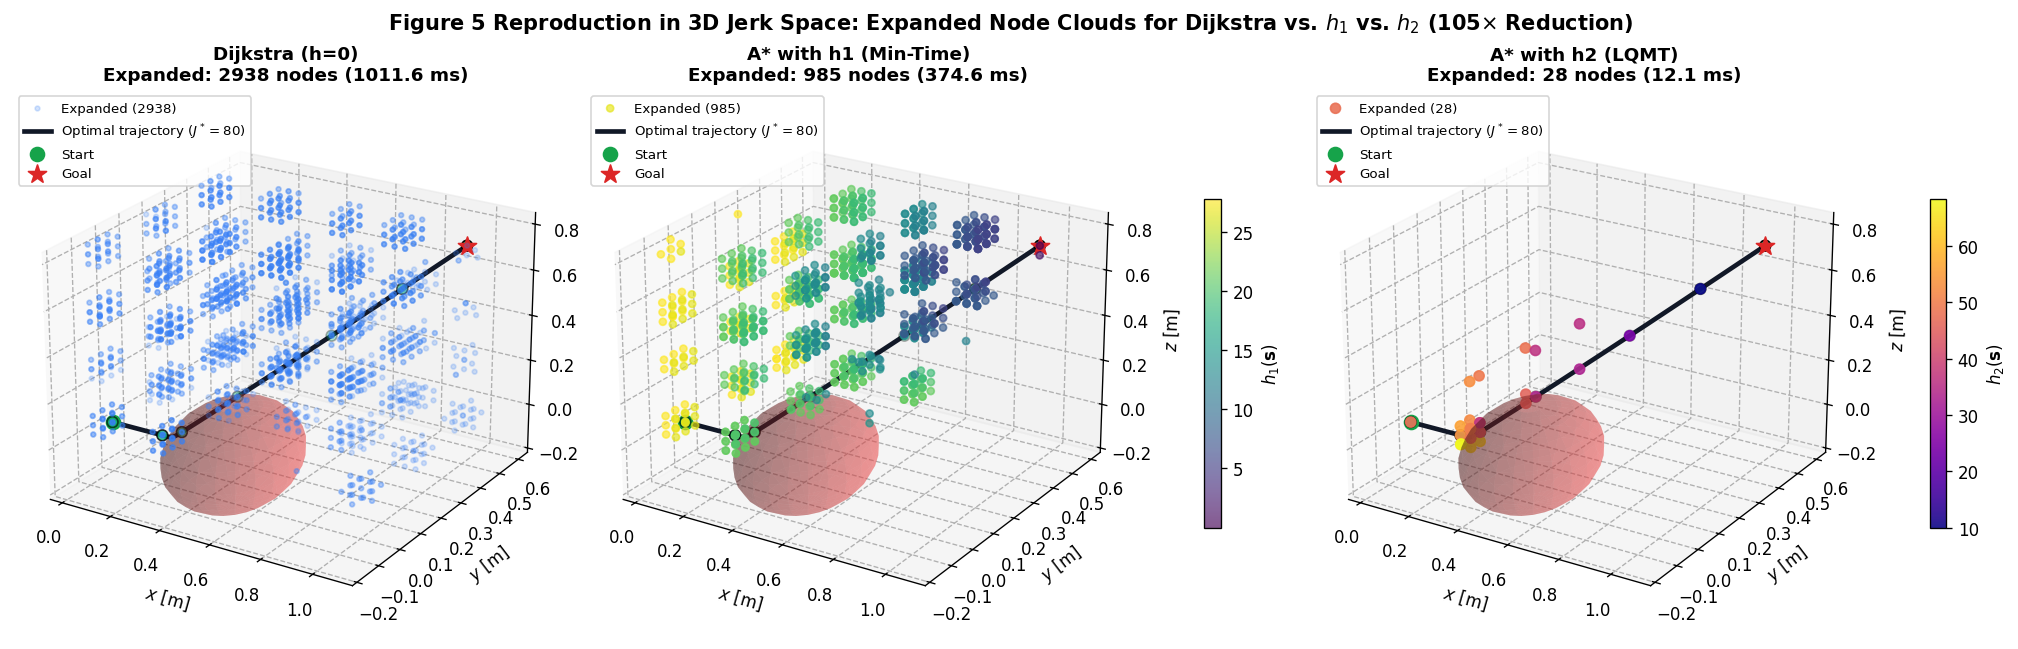

In [4]:
# Dense evaluation of the optimal trajectory for plotting
t_dense_seg = jnp.linspace(0.0, tau, 41)


def sample_full_trajectory(knots, u_seq):
    segs = [
        jax.vmap(lambda t: F_mat(t) @ knots[k] + jnp.outer(G_vec(t), u_seq[k]))(t_dense_seg)
        for k in range(u_seq.shape[0])
    ]
    t_all = jnp.concatenate([k * tau + t_dense_seg for k in range(u_seq.shape[0])])
    s_all = jnp.concatenate(segs, axis=0)
    return t_all, s_all


t_opt_dense, s_opt_dense = sample_full_trajectory(knots_opt, u_opt)
p_opt_dense = s_opt_dense[:, 0, :]

# Spherical obstacle mesh
u_sph, v_sph = jnp.meshgrid(jnp.linspace(0.0, 2.0 * jnp.pi, 24), jnp.linspace(0.0, jnp.pi, 16))
ox = obs_centers[0, 0] + obs_radii[0] * jnp.cos(u_sph) * jnp.sin(v_sph)
oy = obs_centers[0, 1] + obs_radii[0] * jnp.sin(u_sph) * jnp.sin(v_sph)
oz = obs_centers[0, 2] + obs_radii[0] * jnp.cos(v_sph)

fig, axes = plt.subplots(1, 3, figsize=(16.8, 5.3), subplot_kw={"projection": "3d"}, constrained_layout=True)

configs = [
    ("Dijkstra (h=0)", h_zero, "Blues"),
    ("A* with h1 (Min-Time)", h_min_time, "viridis"),
    ("A* with h2 (LQMT)", h_lqmt, "plasma"),
]

for ax, (label, h_fn, cmap_name) in zip(axes, configs):
    res = search_results[label]
    exp_mask = res["closed"].at[res["goal_idx"]].set(False)
    exp_states = res["states"][exp_mask]
    exp_pos = exp_states[:, 0, :]

    if label == "Dijkstra (h=0)":
        ax.scatter(
            exp_pos[:, 0], exp_pos[:, 1], exp_pos[:, 2],
            color="#3b82f6", s=8, alpha=0.22, label=f"Expanded ({res['n_exp']})",
        )
    else:
        h_vals = jax.vmap(h_fn)(exp_states)
        sc = ax.scatter(
            exp_pos[:, 0], exp_pos[:, 1], exp_pos[:, 2],
            c=h_vals, cmap=cmap_name, s=18 if res["n_exp"] > 100 else 36,
            alpha=0.65 if res["n_exp"] > 100 else 0.9, label=f"Expanded ({res['n_exp']})",
        )
        cbar = fig.colorbar(sc, ax=ax, shrink=0.60, pad=0.13)
        cbar.set_label(r"$h_1(\mathbf{s})$" if "h1" in label else r"$h_2(\mathbf{s})$")

    ax.plot_surface(ox, oy, oz, color="#ef4444", alpha=0.32, edgecolor="none")
    ax.plot(
        p_opt_dense[:, 0], p_opt_dense[:, 1], p_opt_dense[:, 2],
        color="#111827", lw=2.8, label=r"Optimal trajectory ($J^*=80$)",
    )
    ax.scatter(
        knots_opt[:, 0, 0], knots_opt[:, 0, 1], knots_opt[:, 0, 2],
        color="#10b981", s=42, edgecolor="black", zorder=6,
    )
    ax.scatter([s0[0, 0]], [s0[0, 1]], [s0[0, 2]], color="#16a34a", s=70, marker="o", label="Start")
    ax.scatter([s_goal[0, 0]], [s_goal[0, 1]], [s_goal[0, 2]], color="#dc2626", s=130, marker="*", label="Goal")

    ax.set_xlim(-0.05, 1.15)
    ax.set_ylim(-0.22, 0.65)
    ax.set_zlim(-0.22, 0.85)
    ax.set_xlabel(r"$x$ [m]")
    ax.set_ylabel(r"$y$ [m]")
    ax.set_zlabel(r"$z$ [m]")
    ax.view_init(elev=23, azim=-58)
    ax.set_title(f"{label}\nExpanded: {res['n_exp']} nodes ({res['warm_ms']:.1f} ms)")
    ax.legend(loc="upper left", fontsize=8, frameon=True)

fig.suptitle(
    r"Figure 5 Reproduction in 3D Jerk Space: Expanded Node Clouds for Dijkstra vs. $h_1$ vs. $h_2$ (105$\times$ Reduction)",
    fontsize=12.5,
    fontweight="bold",
)
plt.show()


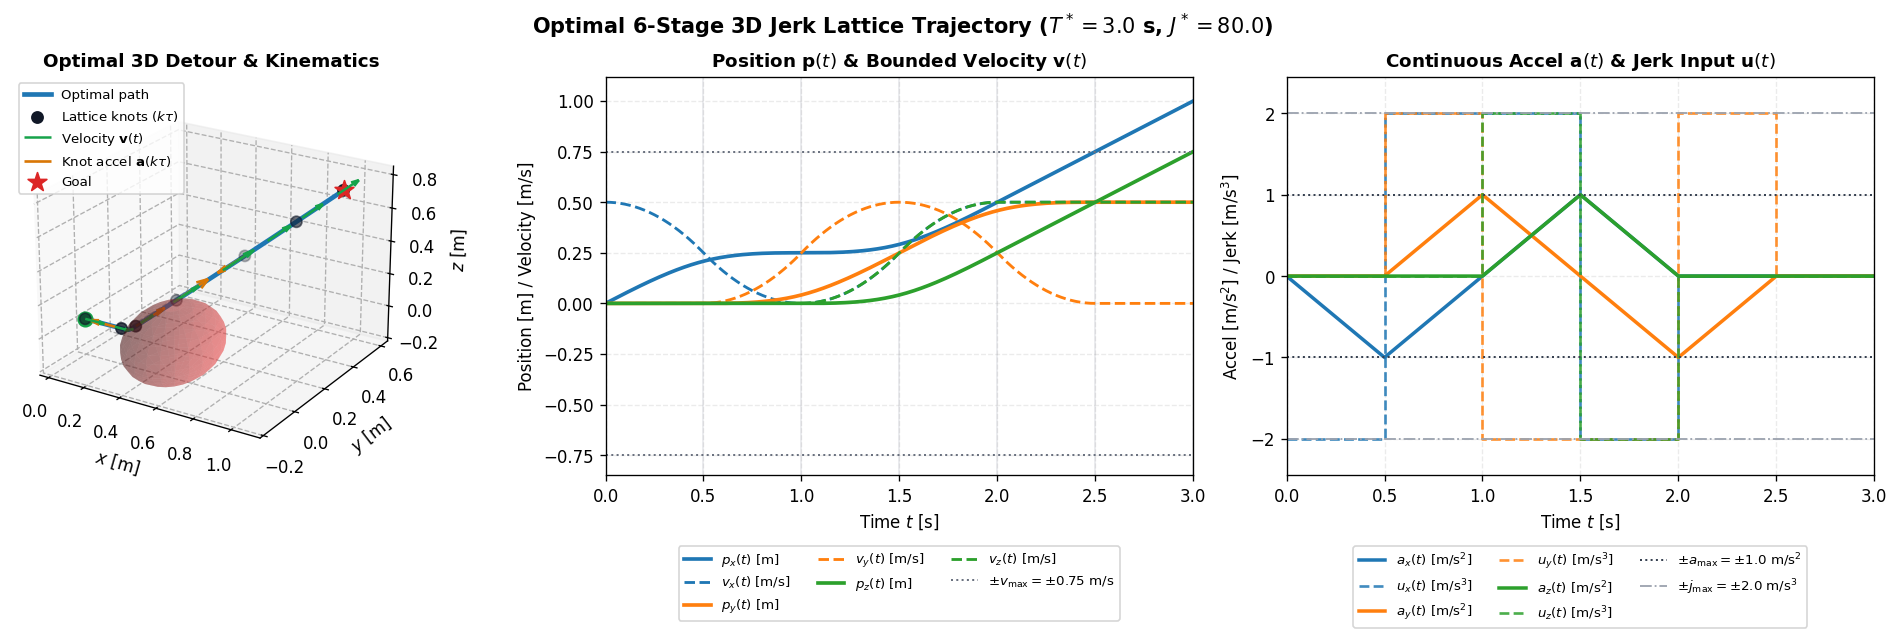

In [5]:
v_opt_dense = s_opt_dense[:, 1, :]
a_opt_dense = s_opt_dense[:, 2, :]
t_knots = jnp.arange(knots_opt.shape[0]) * tau
T_total = float(t_knots[-1])

fig = plt.figure(figsize=(16.5, 5.2), constrained_layout=True)
ax0 = fig.add_subplot(1, 3, 1, projection="3d")
ax1 = fig.add_subplot(1, 3, 2)
ax2 = fig.add_subplot(1, 3, 3)

# Panel 1: 3D optimal trajectory with velocity & acceleration vectors along the path
ax0.plot_surface(ox, oy, oz, color="#ef4444", alpha=0.35, edgecolor="none")
ax0.plot(p_opt_dense[:, 0], p_opt_dense[:, 1], p_opt_dense[:, 2], color="#1f77b4", lw=2.8, label="Optimal path")
ax0.scatter(
    knots_opt[:, 0, 0], knots_opt[:, 0, 1], knots_opt[:, 0, 2],
    color="#111827", s=45, zorder=6, label=r"Lattice knots ($k\tau$)",
)
stride = 30
ax0.quiver(
    p_opt_dense[::stride, 0], p_opt_dense[::stride, 1], p_opt_dense[::stride, 2],
    v_opt_dense[::stride, 0], v_opt_dense[::stride, 1], v_opt_dense[::stride, 2],
    length=0.22, normalize=False, color="#16a34a", lw=1.5, label=r"Velocity $\mathbf{v}(t)$",
)
ax0.quiver(
    knots_opt[:-1, 0, 0], knots_opt[:-1, 0, 1], knots_opt[:-1, 0, 2],
    knots_opt[:-1, 2, 0], knots_opt[:-1, 2, 1], knots_opt[:-1, 2, 2],
    length=0.18, normalize=False, color="#d97706", lw=1.6, label=r"Knot accel $\mathbf{a}(k\tau)$",
)
ax0.scatter([s0[0, 0]], [s0[0, 1]], [s0[0, 2]], color="#16a34a", s=75, marker="o")
ax0.scatter([s_goal[0, 0]], [s_goal[0, 1]], [s_goal[0, 2]], color="#dc2626", s=140, marker="*", label="Goal")
ax0.set_xlim(-0.05, 1.15)
ax0.set_ylim(-0.22, 0.65)
ax0.set_zlim(-0.22, 0.85)
ax0.set_xlabel(r"$x$ [m]")
ax0.set_ylabel(r"$y$ [m]")
ax0.set_zlabel(r"$z$ [m]")
ax0.view_init(elev=23, azim=-58)
ax0.set_title(r"Optimal 3D Detour & Kinematics")
ax0.legend(loc="upper left", fontsize=8, frameon=True)

# Panel 2: Position p(t) and Velocity v(t) vs Time
axis_colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
axis_names = ["x", "y", "z"]
for d in range(3):
    ax1.plot(t_opt_dense, p_opt_dense[:, d], color=axis_colors[d], lw=2.2, label=rf"$p_{axis_names[d]}(t)$ [m]")
    ax1.plot(t_opt_dense, v_opt_dense[:, d], color=axis_colors[d], lw=1.7, ls="--", label=rf"$v_{axis_names[d]}(t)$ [m/s]")
ax1.axhline(v_max, color="#6b7280", ls=":", lw=1.2, label=rf"$\pm v_{{\max}} = \pm {v_max:.2f}$ m/s")
ax1.axhline(-v_max, color="#6b7280", ls=":", lw=1.2)
for tk in t_knots:
    ax1.axvline(float(tk), color="#e5e7eb", lw=0.9, zorder=0)
ax1.set_xlim(0.0, T_total)
ax1.set_ylim(-0.85, 1.12)
ax1.set_xlabel(r"Time $t$ [s]")
ax1.set_ylabel(r"Position [m] / Velocity [m/s]")
ax1.set_title(r"Position $\mathbf{p}(t)$ & Bounded Velocity $\mathbf{v}(t)$")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=8, frameon=True)

# Panel 3: Continuous Acceleration a(t) and Piecewise-Constant Jerk u(t) (Fig. 4e style)
t_step = jnp.append(t_knots[:-1], T_total)
u_step = jnp.vstack([u_opt, u_opt[-1:]])
for d in range(3):
    ax2.plot(t_opt_dense, a_opt_dense[:, d], color=axis_colors[d], lw=2.1, label=rf"$a_{axis_names[d]}(t)$ [m/s$^2$]")
    ax2.step(t_step, u_step[:, d], where="post", color=axis_colors[d], lw=1.6, ls="--", alpha=0.85, label=rf"$u_{axis_names[d]}(t)$ [m/s$^3$]")
ax2.axhline(a_max, color="#374151", ls=":", lw=1.2, label=rf"$\pm a_{{\max}} = \pm {a_max:.1f}$ m/s$^2$")
ax2.axhline(-a_max, color="#374151", ls=":", lw=1.2)
ax2.axhline(j_max, color="#9ca3af", ls="-.", lw=1.1, label=rf"$\pm j_{{\max}} = \pm {j_max:.1f}$ m/s$^3$")
ax2.axhline(-j_max, color="#9ca3af", ls="-.", lw=1.1)
ax2.set_xlim(0.0, T_total)
ax2.set_ylim(-2.45, 2.45)
ax2.set_xlabel(r"Time $t$ [s]")
ax2.set_ylabel(r"Accel [m/s$^2$] / Jerk [m/s$^3$]")
ax2.set_title(r"Continuous Accel $\mathbf{a}(t)$ & Jerk Input $\mathbf{u}(t)$")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=8, frameon=True)

fig.suptitle(
    rf"Optimal {u_opt.shape[0]}-Stage 3D Jerk Lattice Trajectory ($T^* = {T_total:.1f}$ s, $J^* = 80.0$)",
    fontsize=12.5,
    fontweight="bold",
)
plt.show()
